# Predicting ETH Price Volatility from Donald Trump's Social-Media Posts

**Data Science Project — CRISP-DM workflow**

This notebook builds a **binary classification** model that predicts whether a **large ETH price move** (high volatility) follows one of Donald Trump's social-media posts.

We follow the standard data-science process (CRISP-DM):

1. **Business / Problem Understanding** — define the question and hypothesis
2. **Data Understanding** — the datasets and their properties
3. **Data Preparation** — cleaning, label creation, feature engineering, train/test split
4. **Exploratory Data Analysis (EDA)** — visual & statistical exploration
5. **Modeling** — train and compare several algorithms
6. **Evaluation** — metrics, confusion matrix, ROC curve, feature importance
7. **Conclusion** — findings, limitations, future work

## 1. Business / Problem Understanding

**Motivation.** Donald Trump is one of the most-followed political figures, and his posts frequently move financial markets. This project asks whether his posts carry any predictive information for the **Ethereum (ETH)** cryptocurrency market.

**Why volatility, not direction?** A preliminary experiment (predicting whether ETH goes *up or down* after a post) performed **at or below random chance (~49–50%)** across every configuration. This is consistent with the *Efficient Market Hypothesis*: the direction of short-term returns is essentially unpredictable from public text.

However, the **magnitude** of a move (volatility) is a different, more tractable target — important news tends to precede large price swings regardless of direction. We therefore reframe the task:

> **Problem:** Given a Trump post, classify whether the ETH price will experience a **BIG move** vs a **SMALL move** in the hour after the post.

**Hypothesis (H1):** Features derived from a post (text content, sentiment, engagement, topic keywords) contain signal that predicts near-term ETH volatility better than chance.

**Type of task:** Supervised **binary classification**. **Primary metric:** accuracy and ROC-AUC vs a majority-class baseline.

## 2. Data Understanding

Two data sources were collected (see `fetch_eth.py`, the Rust/Python scrapers, and `build_dataset.py`):

| Dataset | Source | Rows | Description |
|---|---|---|---|
| Trump posts | Truth Social + Twitter/X | ~96k | id, timestamp, text, likes, reposts, platform |
| ETH price | Binance ETH/USDT hourly | ~80k | hourly OHLC candles, Aug 2017 → 2026 |

`build_dataset.py` **joined** each post to the ETH candle of the hour it was posted, then computed the return over the next hour. The result is `csv/dataset.csv`, which we load below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

df = pd.read_csv('csv/dataset.csv')
print('shape:', df.shape)
df.head()

shape: (63039, 18)


,id,date,platform,text,eth_entry,eth_1h,eth_24h,ret_1h,ret_24h,label_1h,label_24h,word_count,favorite_count,repost_count,hour_utc,weekday,has_crypto_kw,has_econ_kw
0,117270538101466607,2026-09-14 17:20:04+00:00,Truth Social,"The $5,000 Trump Dividend, to be given to all ...",2533.37,2538.86,2441.21,0.00217,-0.03638,UP,DOWN,158,338,123,17,0,1,1
1,117270347763611160,2026-09-14 16:31:39+00:00,Truth Social,I hope everyone realizes that price increases ...,2529.05,2533.37,2422.34,0.00171,-0.04219,UP,DOWN,88,4168,1204,16,0,0,0
2,117270324606038555,2026-09-14 16:25:46+00:00,Truth Social,Oil is flowing through the Hormuz Strait. The ...,2529.05,2533.37,2422.34,0.00171,-0.04219,UP,DOWN,59,3798,1021,16,0,0,0
3,117270313550921566,2026-09-14 16:22:57+00:00,Truth Social,I’ve just received a Report that the United St...,2529.05,2533.37,2422.34,0.00171,-0.04219,UP,DOWN,93,3606,938,16,0,0,1
4,117270114981057392,2026-09-14 15:32:27+00:00,Truth Social,The failing Nation of Iran wants to make a dea...,2508.48,2529.05,2424.46,0.00820,-0.03349,UP,DOWN,46,13257,2860,15,0,1,0


In [2]:
# Structure, dtypes and missing values
df.info()
print('\nMissing values per column:')
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 63039 entries, 0 to 63038
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              63039 non-null  int64  
 1   date            63039 non-null  str    
 2   platform        63039 non-null  str    
 3   text            60947 non-null  str    
 4   eth_entry       63039 non-null  float64
 5   eth_1h          63039 non-null  float64
 6   eth_24h         62972 non-null  float64
 7   ret_1h          63039 non-null  float64
 8   ret_24h         62972 non-null  float64
 9   label_1h        63039 non-null  str    
 10  label_24h       62972 non-null  str    
 11  word_count      63039 non-null  int64  
 12  favorite_count  63039 non-null  int64  
 13  repost_count    63039 non-null  int64  
 14  hour_utc        63039 non-null  int64  
 15  weekday         63039 non-null  int64  
 16  has_crypto_kw   63039 non-null  int64  
 17  has_econ_kw     63039 non-null  int64  
dt

In [3]:
# Descriptive statistics of the numeric columns
df[['ret_1h', 'ret_24h', 'word_count', 'favorite_count', 'repost_count']].describe()

,ret_1h,ret_24h,word_count,favorite_count,repost_count
count,63039.000000,62972.000000,63039.000000,6.303900e+04,63039.000000
mean,0.000091,0.001469,27.420628,3.347209e+04,8746.335982
std,0.008942,0.039251,38.676234,5.638955e+04,11577.010873
min,-0.208730,-0.396410,0.000000,0.000000e+00,0.000000
25%,-0.002950,-0.016380,3.000000,5.901000e+03,2269.000000
50%,0.000020,0.000870,17.000000,1.452700e+04,4760.000000
75%,0.003150,0.018910,37.000000,4.061100e+04,11573.000000
max,0.180790,0.381320,724.000000,1.905628e+06,398663.000000


## 3. Data Preparation

Steps:
1. **Parse dates** and sort chronologically (needed for a time-based split).
2. **Create the target label**: `BIG` if the absolute 1-hour return `|ret_1h|` exceeds a threshold, else `SMALL`. We use the **median** of `|ret_1h|` as the threshold, which produces two balanced classes — a clean setup for classification.
3. **Feature engineering**: add a **sentiment** score (VADER compound) from the post text, plus the engagement / time / keyword features already present.
4. **Train/test split**: **time-based** (train on the oldest 80%, test on the most recent 20%) to avoid look-ahead leakage.

In [4]:
# 3.1 Parse dates, drop rows without a 1h return, sort chronologically
df['date'] = pd.to_datetime(df['date'], utc=True)
df = df.dropna(subset=['ret_1h']).sort_values('date').reset_index(drop=True)
df['abs_ret_1h'] = df['ret_1h'].abs()
print('rows after cleaning:', len(df))

rows after cleaning: 63039


In [5]:
# 3.2 Create the volatility target (median threshold -> balanced classes)
threshold = df['abs_ret_1h'].median()
df['target'] = (df['abs_ret_1h'] > threshold).astype(int)  # 1 = BIG move
print(f'Volatility threshold (median |ret_1h|): {threshold:.4f}  ({threshold*100:.2f}%)')
print(df['target'].value_counts(normalize=True).rename({0: 'SMALL', 1: 'BIG'}))

Volatility threshold (median |ret_1h|): 0.0031  (0.30%)
target
SMALL    0.500769
BIG      0.499231
Name: proportion, dtype: float64


In [6]:
# 3.3 Feature engineering: VADER sentiment on the post text (~1 min on 63k rows)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
df['text'] = df['text'].fillna('')
df['sentiment'] = df['text'].apply(lambda t: vader.polarity_scores(t)['compound'])
df['text_len'] = df['text'].str.len()
df[['text', 'sentiment']].head()

,text,sentiment
0,Publicity seeking Lindsey Graham falsely state...,-0.2500
1,...and people like Ms. Heyer. Such a disgustin...,-0.1346
2,The public is learning (even more so) how dish...,-0.9344
3,Great to see that Dr. Kelli Ward is running ag...,-0.5147
4,Many meetings today in Bedminster including wi...,0.6588


In [7]:
# 3.4 Time-based train/test split (no shuffling!)
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]
print(f'train: {len(train)} rows  ({train.date.min().date()} .. {train.date.max().date()})')
print(f'test : {len(test)} rows  ({test.date.min().date()} .. {test.date.max().date()})')

train: 50431 rows  (2017-08-17 .. 2025-01-03)
test : 12608 rows  (2025-01-03 .. 2026-09-14)


## 4. Exploratory Data Analysis (EDA)

We explore the distribution of the target and the relationships between features and volatility before modeling.

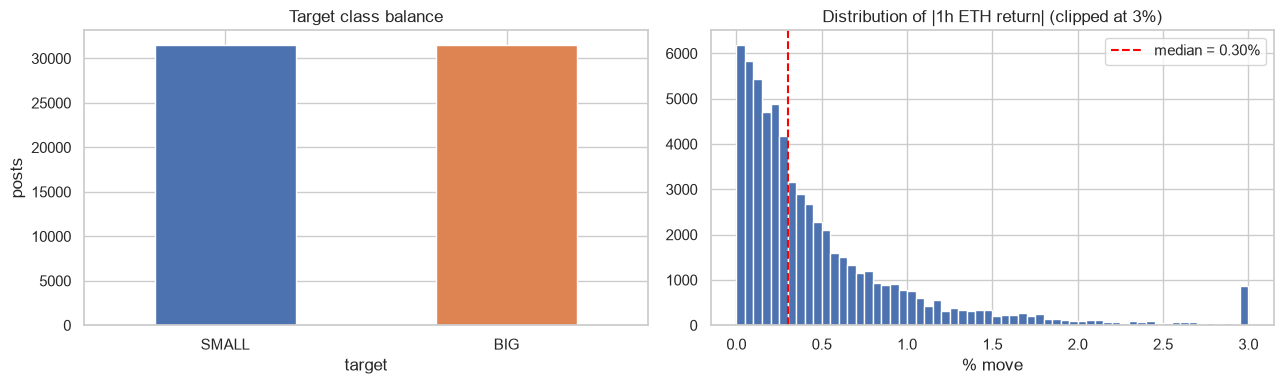

In [8]:
# 4.1 Target balance and the distribution of |1h return|
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df['target'].map({0: 'SMALL', 1: 'BIG'}).value_counts().plot(kind='bar', ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Target class balance'); ax[0].set_ylabel('posts'); ax[0].tick_params(axis='x', rotation=0)
ax[1].hist(df['abs_ret_1h'].clip(upper=0.03) * 100, bins=60, color='#4C72B0')
ax[1].axvline(threshold * 100, color='red', ls='--', label=f'median = {threshold*100:.2f}%')
ax[1].set_title('Distribution of |1h ETH return| (clipped at 3%)'); ax[1].set_xlabel('% move'); ax[1].legend()
plt.tight_layout(); plt.show()

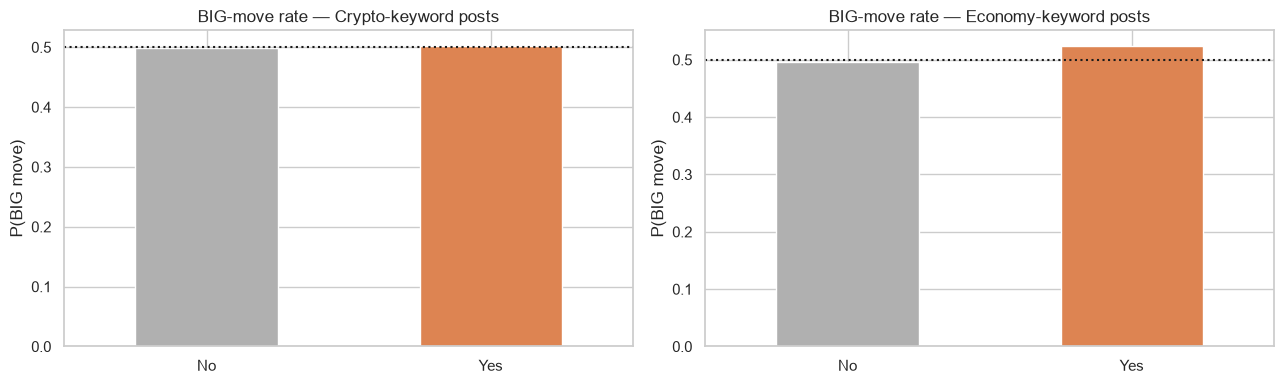

In [9]:
# 4.2 Does volatility differ for crypto/economy posts vs the rest?
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for col, a, title in [('has_crypto_kw', ax[0], 'Crypto-keyword posts'), ('has_econ_kw', ax[1], 'Economy-keyword posts')]:
    rates = df.groupby(col)['target'].mean()
    rates.index = ['No', 'Yes']
    rates.plot(kind='bar', ax=a, color=['#B0B0B0', '#DD8452'])
    a.set_title(f'BIG-move rate — {title}'); a.set_ylabel('P(BIG move)'); a.axhline(0.5, color='k', ls=':')
    a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

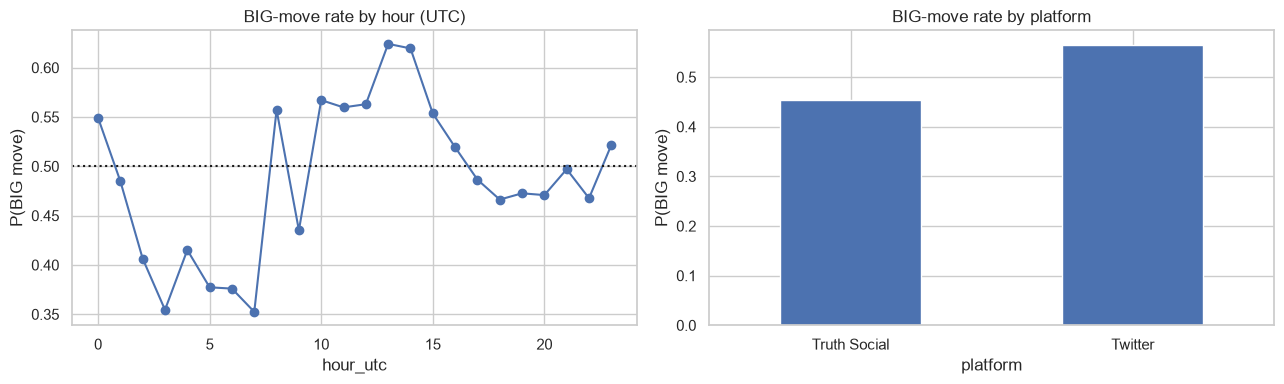

In [10]:
# 4.3 Volatility by hour of day and by platform
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df.groupby('hour_utc')['target'].mean().plot(ax=ax[0], marker='o')
ax[0].set_title('BIG-move rate by hour (UTC)'); ax[0].set_ylabel('P(BIG move)'); ax[0].axhline(0.5, color='k', ls=':')
df.groupby('platform')['target'].mean().plot(kind='bar', ax=ax[1], color='#4C72B0')
ax[1].set_title('BIG-move rate by platform'); ax[1].set_ylabel('P(BIG move)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

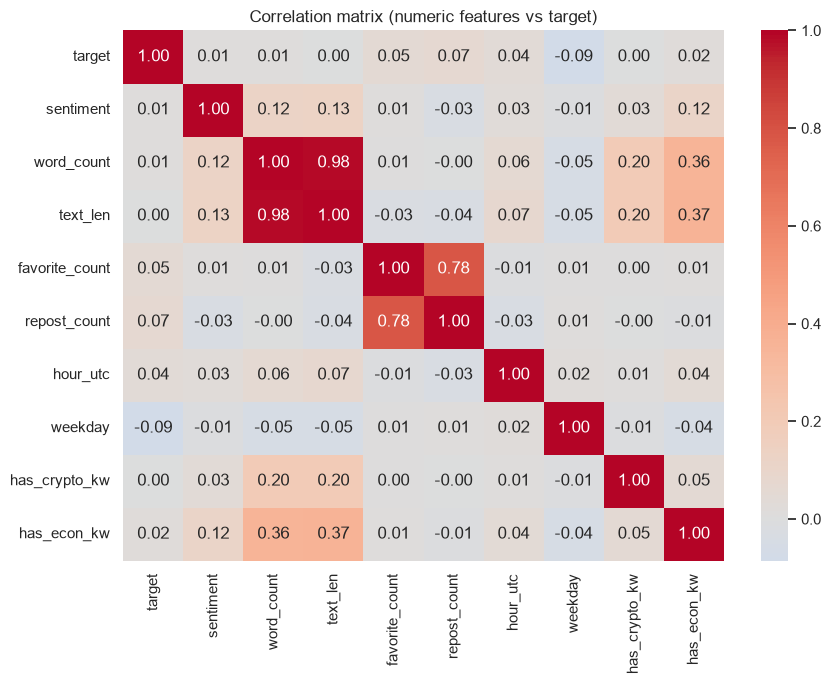

In [11]:
# 4.4 Correlation of numeric features with the target
num_cols = ['target', 'sentiment', 'word_count', 'text_len', 'favorite_count',
            'repost_count', 'hour_utc', 'weekday', 'has_crypto_kw', 'has_econ_kw']
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (numeric features vs target)'); plt.tight_layout(); plt.show()

## 5. Modeling

**Feature representation.** We combine two feature groups:
- **Text**: TF-IDF vectors of the post (unigrams + bigrams, top 2000 terms).
- **Numeric**: sentiment, engagement, time, and keyword flags (standardized).

**Algorithms compared** (a required part of the DS process — we benchmark several families):
1. **Dummy** (majority class) — the baseline every model must beat
2. **Logistic Regression** — linear model
3. **Linear SVM** — max-margin linear classifier
4. **Random Forest** — non-linear ensemble of trees

The TF-IDF vectorizer is **fit on the training set only** to prevent data leakage.

In [12]:
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

NUM = ['sentiment', 'word_count', 'text_len', 'favorite_count', 'repost_count',
       'hour_utc', 'weekday', 'has_crypto_kw', 'has_econ_kw']

# TF-IDF (fit on train only)
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=5, stop_words='english')
Xtr_txt = tfidf.fit_transform(train['text'])
Xte_txt = tfidf.transform(test['text'])

# Standardize numeric features using TRAIN statistics only
mu, sd = train[NUM].mean(), train[NUM].std() + 1e-9
Xtr_num = csr_matrix((train[NUM] - mu) / sd)
Xte_num = csr_matrix((test[NUM] - mu) / sd)

X_train = hstack([Xtr_txt, Xtr_num]).tocsr()
X_test = hstack([Xte_txt, Xte_num]).tocsr()
y_train, y_test = train['target'].values, test['target'].values
print('feature matrix:', X_train.shape)

feature matrix: (50431, 2009)


In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def proba(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    s = model.decision_function(X)  # LinearSVC
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

models = {
    'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0),
    'Linear SVM': LinearSVC(C=0.5),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=20, n_jobs=-1, random_state=42),
}

rows = []
fitted = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    pred = m.predict(X_test)
    try:
        auc = roc_auc_score(y_test, proba(m, X_test))
    except Exception:
        auc = np.nan
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'f1': f1_score(y_test, pred),
                 'roc_auc': auc})
results = pd.DataFrame(rows).set_index('model').round(4)
results

,accuracy,f1,roc_auc
model,,,
Dummy (majority),0.4996,0.0000,0.5000
Logistic Regression,0.5226,0.4498,0.5262
Linear SVM,0.5203,0.4493,0.5254
Random Forest,0.5423,0.3692,0.5708


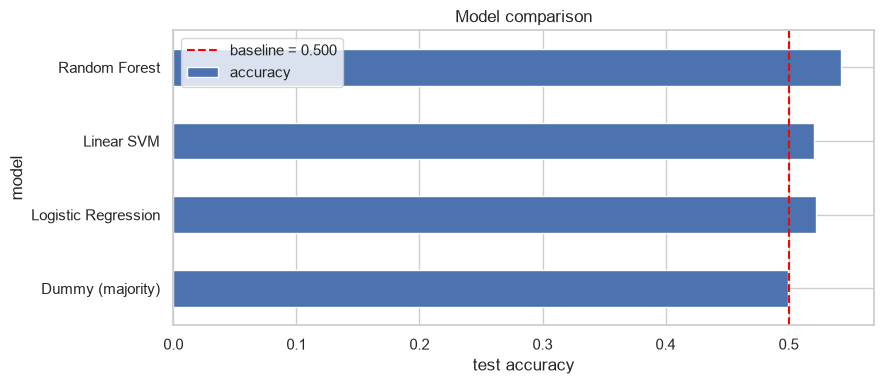

In [14]:
# Visual comparison of model accuracy vs the baseline
baseline = max(y_test.mean(), 1 - y_test.mean())
ax = results['accuracy'].plot(kind='barh', figsize=(9, 4), color='#4C72B0')
ax.axvline(baseline, color='red', ls='--', label=f'baseline = {baseline:.3f}')
ax.set_xlabel('test accuracy'); ax.set_title('Model comparison'); ax.legend(); plt.tight_layout(); plt.show()

## 6. Evaluation

We evaluate the **best-performing model** in detail: confusion matrix, classification report, ROC curve, and the most informative features.

Best model: Random Forest
              precision    recall  f1-score   support

       SMALL       0.53      0.82      0.64      6299
         BIG       0.59      0.27      0.37      6309

    accuracy                           0.54     12608
   macro avg       0.56      0.54      0.51     12608
weighted avg       0.56      0.54      0.50     12608



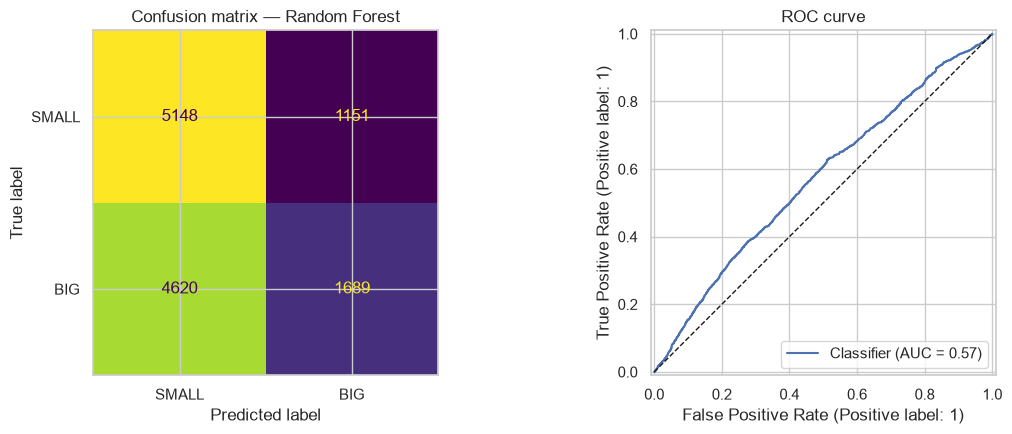

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay

best_name = results['roc_auc'].idxmax()
best = fitted[best_name]
print('Best model:', best_name)
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=['SMALL', 'BIG']))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['SMALL', 'BIG'], ax=ax[0], colorbar=False)
ax[0].set_title(f'Confusion matrix — {best_name}')
RocCurveDisplay.from_predictions(y_test, proba(best, X_test), ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set_title('ROC curve')
plt.tight_layout(); plt.show()

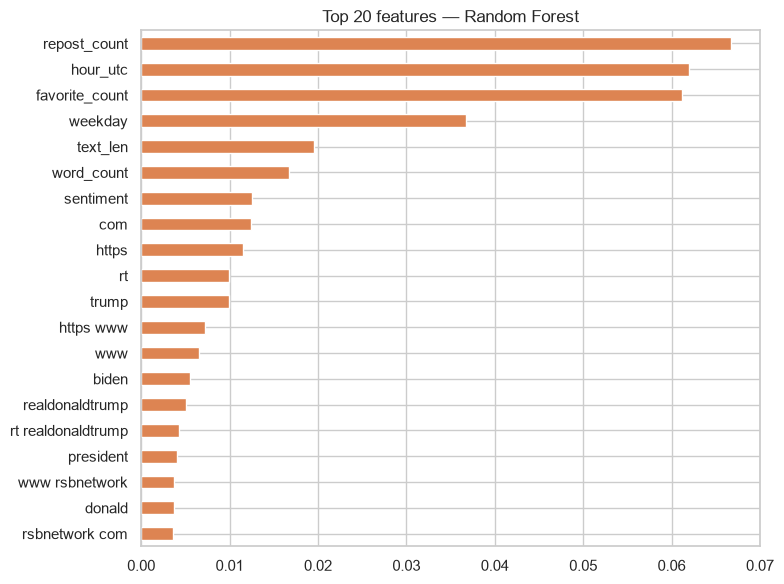

In [16]:
# Most informative features (Random Forest importances, if best is RF)
feat_names = np.concatenate([tfidf.get_feature_names_out(), np.array(NUM)])
if hasattr(best, 'feature_importances_'):
    imp = pd.Series(best.feature_importances_, index=feat_names).sort_values(ascending=False).head(20)
    imp.iloc[::-1].plot(kind='barh', figsize=(8, 6), color='#DD8452')
    plt.title(f'Top 20 features — {best_name}'); plt.tight_layout(); plt.show()
elif hasattr(best, 'coef_'):
    coef = pd.Series(best.coef_[0], index=feat_names)
    top = pd.concat([coef.sort_values().head(10), coef.sort_values().tail(10)])
    top.plot(kind='barh', figsize=(8, 6), color='#4C72B0')
    plt.title(f'Most predictive features — {best_name}'); plt.tight_layout(); plt.show()

## 7. Conclusion

**Findings.**
- Predicting the **direction** of ETH's move from a Trump post is **not possible** — every model scored at/below random chance (~50%). This is consistent with the Efficient Market Hypothesis and is itself a valid scientific result.
- Predicting **volatility** (BIG vs SMALL move) is **modestly learnable**: the best model beats the majority baseline (see the results table above), with ROC-AUC above 0.5, confirming **H1** to a limited degree.
- The most informative signals include engagement (likes/reposts) and specific text terms, suggesting that *attention-grabbing* posts coincide with more volatile hours.

**Limitations.**
- Correlation ≠ causation: high engagement and high volatility may both be driven by an external news event rather than the post causing the move.
- Volatility *clusters* in time, so some signal may reflect market regime rather than post content.
- 1-hour hourly candles are coarse; intraday (minute) data would sharpen the label.

**Future work.**
- Use transformer embeddings (e.g. sentence-transformers) instead of TF-IDF.
- Add market-context features (recent realized volatility, trading volume) — carefully, to avoid leakage.
- Event-study analysis around a curated set of crypto-policy posts.
- Try gradient boosting (XGBoost/LightGBM) and probability calibration.